In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import jax
from jax.typing import ArrayLike
from jax import numpy as jnp # JAX version of NumPy.
from flax import nnx # Neural networks in JAX.
import optax # Optimization in JAX.
import gymnasium as gym
import numpy as np # For compatibility with gymnasium.
from tqdm import tqdm
import pennylane as qml
import json
import yaml
import tyro
from pathlib import Path
import qnrl
import matplotlib.pyplot as plt
import pandas as pd

jax.config.update("jax_enable_x64", True) # Enable double-precision (default is single-precision).

In [3]:
import wandb

wandb.login()

wandb: Currently logged in as: zanderman (zanderman-virginia-tech) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


True

In [4]:
# Create default configuration storage object.
store = qnrl.store.HashStore()

In [5]:
def inspect_model_pmfs_for_observation(obs, model, atoms):
    """Display the model return-atom density matrix for a given observation."""
    
    # Put single observation into a 1-batch for input to model.
    observations = jnp.array([obs])

    # Generate action PMF for current observation.
    return_pmfs = model(observations)
    return_pmfs = return_pmfs[0] # There's only 1 item in batch.
    
    
    ## Display the observation.
    print(f"{observations = }")
    
    # Compute Q-value for each action.
    Q = jnp.array([jnp.sum(rpmf * atoms) for a, rpmf in enumerate(return_pmfs)])
    
    for a, q in enumerate(Q):
        print(f"Q(a{a}): {q}")
    
    best_action = jnp.argmax(Q)
    print(f"{best_action.item() = }")
    
    figures = []
    
    
    
    ### Show a matplotlib figure for PDF render.
    #
    ## Action PMF.
    # fig = plt.figure()
    # ax = fig.add_subplot(111)
    # x = jnp.arange(action_pmf[0].shape[-1])
    # ax.bar(x, action_pmf[0])
    # ax.set_xticks(x, [f"$a_{{{i}}}$" for i in range(len(x))], rotation=90)
    # ax.set_xlabel("Action atom")
    # ax.set_ylabel("Probability")
    # ax.set_title("Action PMF based on return-atom amplitude kickback")
    #
    ## Plot the return PMF for each action individually.
    n_actions, n_returns = return_pmfs.shape
    fig = plt.figure()
    x = jnp.arange(n_returns)
    fig, axs = plt.subplots(n_actions, 1, sharex=True, sharey=True)
    figures.append(fig)
    axs = axs.flatten()
    for a in range(n_actions):
        axs[a].bar(jnp.arange(n_returns), return_pmfs[a])
        axs[a].set_xticks(x, [f"$z_{{{i}}}$" for i in range(len(x))], rotation=90)
        axs[a].set_title(f"$a_{{{a}}}$")
        axs[a].set_xlabel("Return atom")
        axs[a].set_ylabel("Probability")
    fig.suptitle("Return-atom PMF for each action $a_i$")
    plt.tight_layout()
    
    return figures

def inspect_model_pmfs_for_env(env, model, atoms):
    """Display the model return-atom density matrix for a random environment observation."""
    
    # Generate a batch of environment observations.
    # observations = jnp.array([env.reset()[0] for _ in range(config.batch_size)])
    # 
    obs = env.reset()[0]
    # for _ in range(10): obs = env.step(0)[0] # Mutate the environment to get a different observation.
    # observations = jnp.array([obs for _ in range(config.batch_size)])
    figures = inspect_model_pmfs_for_observation(obs, model, atoms)
    
    return obs, figures

In [ ]:
from qnrl.algorithms.c51 import C51
from qnrl.optimizer import *
from qnrl.environment import *
from qnrl.modules import Sequential, DistQNetworkLinear

import ale_py
gym.register_envs(ale_py)

# # CartPole.
# env_id = "CartPole-v1"
# env = EnvConfig(env_id=env_id)
# din = 4
# num_actions = 2
# z_min = -100
# z_max = 100
# total_timesteps = 100_000
# ##
# # z_min = 0
# # z_max = 500
# ##
# # douts = [16,8]
# douts = [30,21]
# # douts = [60,42]
# ###

# FrozenLake-v1
env_id = "FrozenLake-v1"
# din = 1
din = 16
num_actions = 4
# env = EnvConfig(env_id=env_id)
# env = ObservationExpandDims(env=EnvConfig(env_id=env_id), axis=0)
# env = ObservationExpandDims(env=EnvConfig(env_id=env_id, extra_args=dict(reward_schedule=(2,-1,-0.01))), axis=0)
# env = ObservationDiscreteOneHot(env=EnvConfig(env_id=env_id, extra_args=dict(reward_schedule=(2,-1,-0.01))))
env = ObservationDiscreteOneHot(env=EnvConfig(env_id=env_id, extra_args=dict(reward_schedule=(1.0,-0.2,-0.01), map_name="4x4"), max_episode_steps=100)) # See reward schedule from https://ieeexplore.ieee.org/document/9144562
# z_min = -100
# z_max = 100
###
# z_min = -2
# z_max = 1
###
z_min = -2
z_max = 2
###
total_timesteps = 100_000
# douts = [30,21]
douts = [15,10]
# douts = [7,5]

# CliffWalking-v1
# din = 1
# din = 2
din = 48
num_actions = 4
env_id = "CliffWalking-v1"
# env = EnvConfig(env_id="CliffWalking-v1")
# env = ObservationExpandDims(env=EnvConfig(env_id=env_id, max_episode_steps=99), axis=0)
env = ObservationDiscreteOneHot(env=EnvConfig(env_id=env_id, max_episode_steps=99))
# env = ObservationDiscreteUnravel(env=EnvConfig(env_id=env_id, max_episode_steps=99), shape=(4,12))
z_min = -100
z_max = 100
total_timesteps = 100_000
# douts = [30,21]
# douts = [15,10]
# douts = [7,5]
douts = [4,2]

# # MountainCar.
# env_id = "MountainCar-v0"
# env = EnvConfig(env_id=env_id)
# din = 2
# num_actions = 3
# z_min = -100
# z_max = 100
# ###
# # z_min = -200
# # z_max = -1
# ###
# total_timesteps = 100_000
# douts = [30,21]

# # Acrobot-v1
# din = 6
# num_actions = 3
# env = EnvConfig(env_id="Acrobot-v1")
# z_min = -100
# z_max = 100
# total_timesteps = 100_000
# ###
# # z_min = -500
# # z_max = -1
# ###
# douts = [30,21]
# # douts = [60,42]



# # ALE/Asteroids-v5
# din = 128
# num_actions = 14
# env = EnvConfig(env_id="ALE/Asteroids-v5", extra_args=dict(obs_type="ram"))
# z_min = 1
# z_max = 10000

# num_atoms = 101
# num_atoms = 2**7
num_atoms = 2**5

batch_size = 128

seed = 0
# seed = 21
# seed = 42
# seed = 73
# seed = 96

# Experiment configuration.
config = C51(
    buffer_size=10_000,
    seed=seed,
    batch_size=batch_size,
    # total_timesteps=500_000,
    # total_timesteps=100_000,
    # total_timesteps=50_000,
    # total_timesteps=20_000, # quick test default.
    total_timesteps=total_timesteps,
    learning_starts=10_000,
    policy_update_frequency=10,
    target_update_frequency=500,
    gamma=0.99, # default
    # gamma=0.95,
    tau=1.0,
    eps_start=1,
    eps_end=5e-2,
    eps_exploration=0.5, # default
    # eps_exploration=0.75,
    #
    # env=EnvConfig(env_id="CartPole-v1"),
    # env=EnvConfig(env_id="MountainCar-v0"),
    env=env,
    num_atoms=num_atoms,
    z_min=z_min,
    z_max=z_max,
    model=DistQNetworkLinear(
        din=din,
        num_actions=num_actions,
        num_atoms=num_atoms,
        # douts=[120, 84],
        # douts=[120,],
        # douts=[60,42], # Does well at 20,000 epochs.
        # douts=[30,21], # Does not solve at 20,000 epochs.
        # douts=[15,10],
        # douts=[16,8],
        # douts=[30,],
        # douts=[60,],
        douts=douts,
        rngs_kwargs=dict(default=seed),
    ),
    # model=Sequential(
    #     layers={
    #         # 'RescaleInput': RescaleInput(scale=[2.4, 2.5, 0.21, 2.5]),
    #         'QNetworkLinear': DistQNetworkLinear(
    #             din=din,
    #             num_actions=num_actions,
    #             num_atoms=num_atoms,
    #             # douts=[120, 84],
    #             # douts=[120,],
    #             # douts=[60,42], # Does well at 20,000 epochs.
    #             # douts=[30,21], # Does not solve at 20,000 epochs.
    #             # douts=[15,10],
    #             # douts=[16,8],
    #             # douts=[30,],
    #             # douts=[60,],
    #             douts=douts,
    #             rngs_kwargs=dict(default=seed),
    #         ),
    #     },
    # ),
    # optimizer=Adam(learning_rate=2.5e-4),
    # optimizer=Adam(learning_rate=2.5e-3),
    # optimizer=Adam(learning_rate=1e-3, eps=0.01/batch_size),
    optimizer=Adam(learning_rate=1e-3),
)

if store.exists(config):
    print(f"Already exists in store")
    cfg_hash, cfg_str = store.hash(config)
else:
    print(f"New hash")
    # Generate hash for the current config and store it for later retrieval.
    cfg_hash, cfg_str = store.store_obj(config)

print(f"Config String: {cfg_str}")
print(f"Config Hash: {cfg_hash}")

Already exists in store
Config String: {"type": "C51", "env": {"type": "ObservationDiscreteOneHot", "env": {"type": "EnvConfig", "env_id": "CliffWalking-v1", "render_mode": null, "max_episode_steps": 99, "extra_args": null}, "num_classes": null}, "seed": 0, "metric_manager": null, "checkpoint": null, "train_meta_prefix_key": "train/", "eval_meta_prefix_key": "eval/", "model": {"type": "DistQNetworkLinear", "din": 48, "num_actions": 4, "num_atoms": 32, "douts": [4, 2], "rngs_kwargs": {"default": 0}}, "optimizer": {"type": "Adam", "learning_rate": 0.001, "b1": 0.9, "b2": 0.999, "eps": 1e-08, "eps_root": 0.0, "mu_dtype": null, "nesterov": false}, "num_atoms": 32, "z_min": -100.0, "z_max": 100.0, "buffer_size": 10000, "batch_size": 128, "total_timesteps": 100000, "learning_starts": 10000, "policy_update_frequency": 10, "target_update_frequency": 500, "gamma": 0.99, "tau": 1.0, "eps_start": 1.0, "eps_end": 0.05, "eps_exploration": 0.5, "reseed_model_on_init": false}
Config Hash: 28bea1fd-34

In [ ]:
from qnrl.algorithms.algorithm import Algorithm
tmp = Algorithm.from_dict({'batch_size': 128, 'buffer_size': 10000, 'env': {'env': {'env_id': 'FrozenLake-v1', 'extra_args': {'map_name': '4x4', 'reward_schedule': [1, -0.2, -0.01]}, 'max_episode_steps': 100, 'type': 'EnvConfig'}, 'type': 'ObservationDiscreteOneHot'}, 'eps_end': 0.05, 'eps_exploration': 0.5, 'eps_start': 1, 'gamma': 0.99, 'learning_starts': 10000, 'model': {'din': 16, 'douts': [4, 2], 'num_actions': 4, 'num_atoms': 32, 'rngs_kwargs': {'default': 0}, 'type': 'DistQNetworkLinear'}, 'num_atoms': 32, 'optimizer': {'learning_rate': 0.001, 'type': 'Adam'}, 'policy_update_frequency': 10, 'reseed_model_on_init': True, 'seed': 21, 'target_update_frequency': 500, 'tau': 1, 'total_timesteps': 100000, 'type': 'C51', 'z_max': 2, 'z_min': -2})

e = tmp.env.make()
e.unwrapped.
# e.reset()
# e.step(0)

In [14]:
eval_history_df, eval_report = config.eval(seed=12445)





  0%|          | 229/100000 [00:00<01:47, 930.88step/s, eval/step=229, eval/episode_reward=-229, eval/episode_length=230, eval/episode_time=0.246]


In [15]:
from IPython.display import HTML
HTML(pd.DataFrame([eval_report]).iloc[0]['eval/video'].to_html5_video())

CalledProcessError: Command '['ffmpeg', '-f', 'rawvideo', '-vcodec', 'rawvideo', '-s', '1000x500', '-pix_fmt', 'rgba', '-framerate', '14.999999999999998', '-loglevel', 'error', '-i', 'pipe:', '-vcodec', 'h264', '-pix_fmt', 'yuv420p', '-y', '/var/folders/t7/1jlv9_sn36g96901km63r92m0000gn/T/tmpb9xsgt4i/temp.m4v']' returned non-zero exit status 255.

In [85]:
eval_report

{'eval/seed': 12445,
 'eval/total_model_parameter_count': 2973,
 'eval/step': 229,
 'eval/episode_reward': -229.0,
 'eval/episode_length': 230,
 'eval/episode_time': 0.244405,
 'eval/video': <matplotlib.animation.FuncAnimation at 0x315758830>}

In [86]:
HTML(eval_report['eval/video'].to_html5_video())

In [67]:
from qnrl.algorithms.c51 import generate_video_from_history_OLD
import moviepy
clip = generate_video_from_history_OLD(eval_history_df, meta_prefix_key="eval/", fps=15)
# clip = moviepy.ImageSequenceClip(generate_video_from_history(eval_history_df, meta_prefix_key="eval/"), fps=5)
# clip.preview()
moviepy.display_in_notebook(clip, loop=True, autoplay=True)
# clip.fx(moviepy.vfx.loop, duration=10)

# from IPython.display import HTML
# HTML(clip.to_html5_video())

MoviePy - Building video __temp__.mp4.
MoviePy - Writing video __temp__.mp4



MoviePy - Done !
MoviePy - video ready __temp__.mp4


In [69]:
from qnrl.algorithms.c51 import generate_video_from_history
clip = generate_video_from_history(eval_history_df, meta_prefix_key="eval/", fps=15)
# clip = moviepy.ImageSequenceClip(generate_video_from_history(eval_history_df, meta_prefix_key="eval/"), fps=5)
# clip.preview()
# moviepy.display_in_notebook(clip, loop=True, autoplay=True)
# clip.fx(moviepy.vfx.loop, duration=10)

# clip.to_html5_video()

from IPython.display import HTML
HTML(clip.to_html5_video())

i=0
i=0
i=0
i=0
i=1
i=2
i=3
i=4
i=5
i=6
i=7
i=8
i=9
i=10
i=11
i=12
i=13
i=14
i=15
i=16
i=17
i=18
i=19
i=20
i=21
i=22
i=23
i=24
i=25
i=26
i=27
i=28
i=29
i=30
i=31
i=32
i=33
i=34
i=35
i=36
i=37
i=38
i=39
i=40
i=41
i=42
i=43
i=44
i=45
i=46
i=47
i=48
i=49
i=50
i=51
i=52
i=53
i=54
i=55
i=56
i=57
i=58
i=59
i=60
i=61
i=62
i=63
i=64
i=65
i=66
i=67
i=68
i=69
i=70
i=71
i=72
i=73
i=74
i=75
i=76
i=77
i=78
i=79
i=80
i=81
i=82
i=83
i=84
i=85
i=86
i=87


CalledProcessError: Command '['ffmpeg', '-f', 'rawvideo', '-vcodec', 'rawvideo', '-s', '1000x500', '-pix_fmt', 'rgba', '-framerate', '14.999999999999998', '-loglevel', 'error', '-i', 'pipe:', '-vcodec', 'h264', '-pix_fmt', 'yuv420p', '-y', '/var/folders/t7/1jlv9_sn36g96901km63r92m0000gn/T/tmpil76h341/temp.m4v']' returned non-zero exit status 255.

In [7]:
plt.ioff()
eval_history_df, eval_report = config.eval()

  0%|          | 98/100000 [00:00<01:53, 881.60step/s, eval/step=98, eval/episode_reward=-99, eval/episode_length=99, eval/episode_time=0.118]


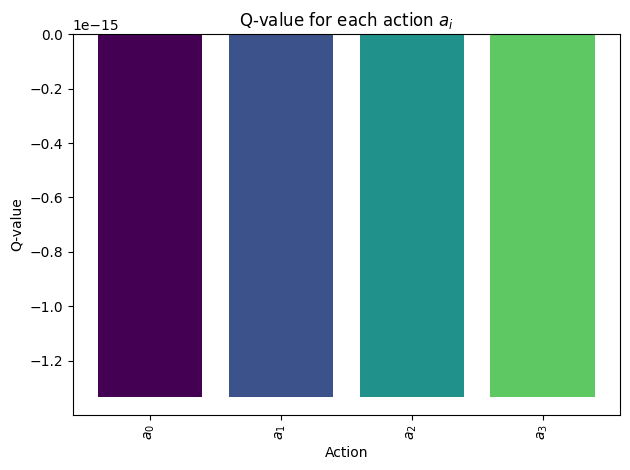

In [12]:
eval_report['eval/inspect'][0]['fig/q_values']

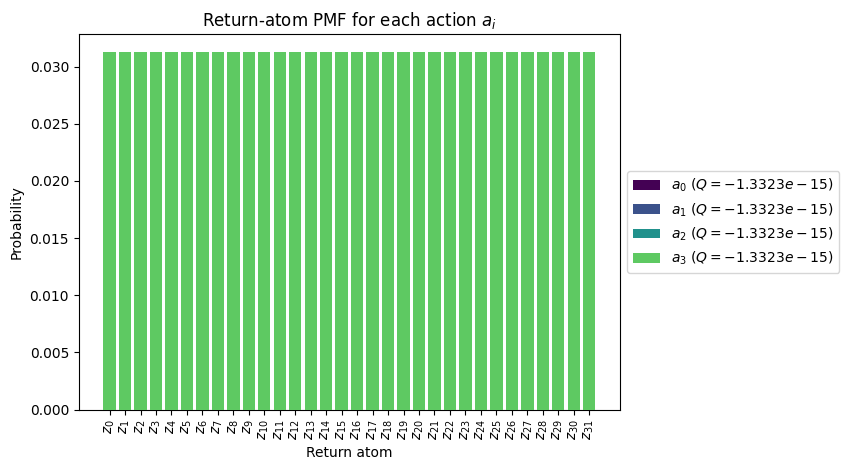

In [13]:
eval_report['eval/inspect'][0]['fig/pmfs']

In [20]:
eval_report['eval/inspect'][0]

{'data/atoms': Array([-100.        ,  -93.5483871 ,  -87.09677419,  -80.64516129,
         -74.19354839,  -67.74193548,  -61.29032258,  -54.83870968,
         -48.38709677,  -41.93548387,  -35.48387097,  -29.03225806,
         -22.58064516,  -16.12903226,   -9.67741935,   -3.22580645,
           3.22580645,    9.67741935,   16.12903226,   22.58064516,
          29.03225806,   35.48387097,   41.93548387,   48.38709677,
          54.83870968,   61.29032258,   67.74193548,   74.19354839,
          80.64516129,   87.09677419,   93.5483871 ,  100.        ],      dtype=float64),
 'data/q_values': Array([-1.33226763e-15, -1.33226763e-15, -1.33226763e-15, -1.33226763e-15],      dtype=float64),
 'data/pmfs': Array([[0.03125, 0.03125, 0.03125, 0.03125, 0.03125, 0.03125, 0.03125,
         0.03125, 0.03125, 0.03125, 0.03125, 0.03125, 0.03125, 0.03125,
         0.03125, 0.03125, 0.03125, 0.03125, 0.03125, 0.03125, 0.03125,
         0.03125, 0.03125, 0.03125, 0.03125, 0.03125, 0.03125, 0.03125,
    

In [ ]:
import moviepy

# from moviepy.video.io import mplfig_to_npimage as fig_to_numpy
# from moviepy.tools import 
# from moviepy.video.io.bindings import mplfig_to_npimage


def fig_to_numpy(fig):
    fig.canvas.draw()
    # data = np.frombuffer(fig.canvas.tostring_argb(), dtype=np.uint8)
    # return data.reshape((*fig.canvas.get_width_height()[::-1],4))

    return np.asarray(fig.canvas.buffer_rgba())

# fig_to_numpy(eval_report['eval/inspect'][0]['fig/q_values']).shape

# fig_to_numpy = lambda fig: np.frombuffer(fig.canvas.tostring_argb(), dtype=np.uint8).reshape((*fig.canvas.get_width_height()[::-1],4))

# clip = moviepy.ImageSequenceClip(list(fig_to_numpy(d['fig/q_values']) for d in eval_report['eval/inspect']), fps=10)
clip = moviepy.ImageSequenceClip(list(fig_to_numpy(d['fig/pmfs']) for d in eval_report['eval/inspect']), fps=5)
clip.preview()

OSError: [Errno 32] Broken pipe

MoviePy error: FFPLAY encountered the following error while previewing clip :

 None

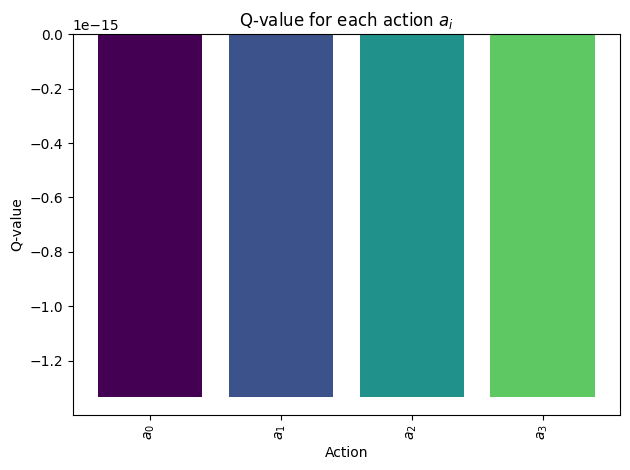

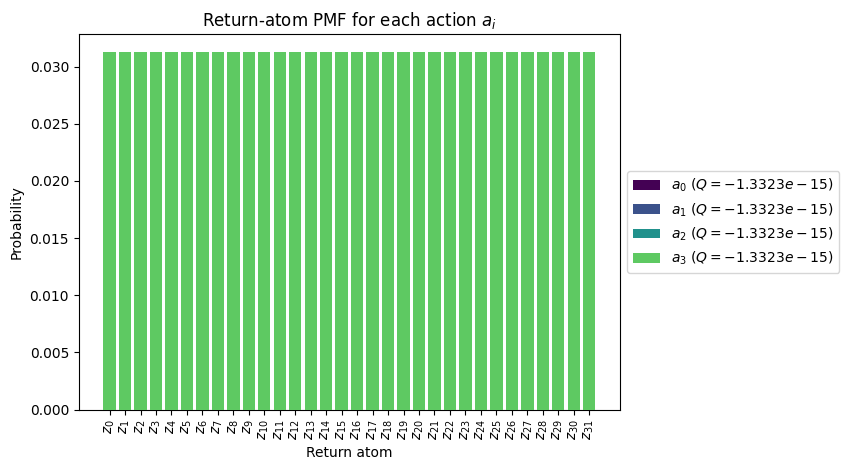

In [7]:
from qnrl.algorithms.c51 import inspect_model_pmfs_for_observation as dummy_inspect

atoms = jnp.linspace(start=config.z_min, stop=config.z_max, num=config.num_atoms)
inspect_meta = dummy_inspect(config.model, atoms, config.env.make().reset()[0])

In [8]:
inspect_meta

{'data/atoms': Array([-100.        ,  -93.5483871 ,  -87.09677419,  -80.64516129,
         -74.19354839,  -67.74193548,  -61.29032258,  -54.83870968,
         -48.38709677,  -41.93548387,  -35.48387097,  -29.03225806,
         -22.58064516,  -16.12903226,   -9.67741935,   -3.22580645,
           3.22580645,    9.67741935,   16.12903226,   22.58064516,
          29.03225806,   35.48387097,   41.93548387,   48.38709677,
          54.83870968,   61.29032258,   67.74193548,   74.19354839,
          80.64516129,   87.09677419,   93.5483871 ,  100.        ],      dtype=float64),
 'data/q_values': Array([-1.33226763e-15, -1.33226763e-15, -1.33226763e-15, -1.33226763e-15],      dtype=float64),
 'data/pmfs': Array([[0.03125, 0.03125, 0.03125, 0.03125, 0.03125, 0.03125, 0.03125,
         0.03125, 0.03125, 0.03125, 0.03125, 0.03125, 0.03125, 0.03125,
         0.03125, 0.03125, 0.03125, 0.03125, 0.03125, 0.03125, 0.03125,
         0.03125, 0.03125, 0.03125, 0.03125, 0.03125, 0.03125, 0.03125,
    

In [9]:
# figs

In [10]:
nnx.state(config.model, nnx.Param)

State({
  'layers': {
    0: {
      'bias': Param( # 4 (16 B)
        value=Array([0., 0., 0., 0.], dtype=float32)
      ),
      'kernel': Param( # 192 (768 B)
        value=Array([[ 0.15446685, -0.13996804, -0.11611269, -0.17876387],
               [-0.13471025,  0.09172336,  0.11242214, -0.15764204],
               [ 0.24358098, -0.26875362, -0.19531181,  0.02092043],
               [-0.17614196,  0.03744733,  0.25318944,  0.0787857 ],
               [ 0.09268003, -0.07380276,  0.14135703,  0.05646113],
               [-0.0986914 , -0.1345989 ,  0.11766541,  0.16309552],
               [ 0.14026974, -0.07682038,  0.13729809,  0.24164729],
               [-0.31252292,  0.06898641,  0.26113042, -0.17901681],
               [-0.09170465,  0.29130873,  0.12425888, -0.03090803],
               [-0.25262624, -0.12721151, -0.30528507,  0.23026894],
               [ 0.21117166,  0.05477571,  0.00978262,  0.17528124],
               [-0.03325309, -0.05310836,  0.10706847, -0.0530404 ],
    

In [11]:
config.model.to_dict()

{'type': 'DistQNetworkLinear',
 'din': 48,
 'num_actions': 4,
 'num_atoms': 32,
 'douts': [4, 2],
 'rngs_kwargs': {'default': 0}}

In [12]:
qnrl.tools.get_model_total_parameter_count(config.model)

590

In [13]:
# Print all the parameters.
nnx.state(config.model, nnx.Param)

State({
  'layers': {
    0: {
      'bias': Param( # 4 (16 B)
        value=Array([0., 0., 0., 0.], dtype=float32)
      ),
      'kernel': Param( # 192 (768 B)
        value=Array([[ 0.15446685, -0.13996804, -0.11611269, -0.17876387],
               [-0.13471025,  0.09172336,  0.11242214, -0.15764204],
               [ 0.24358098, -0.26875362, -0.19531181,  0.02092043],
               [-0.17614196,  0.03744733,  0.25318944,  0.0787857 ],
               [ 0.09268003, -0.07380276,  0.14135703,  0.05646113],
               [-0.0986914 , -0.1345989 ,  0.11766541,  0.16309552],
               [ 0.14026974, -0.07682038,  0.13729809,  0.24164729],
               [-0.31252292,  0.06898641,  0.26113042, -0.17901681],
               [-0.09170465,  0.29130873,  0.12425888, -0.03090803],
               [-0.25262624, -0.12721151, -0.30528507,  0.23026894],
               [ 0.21117166,  0.05477571,  0.00978262,  0.17528124],
               [-0.03325309, -0.05310836,  0.10706847, -0.0530404 ],
    

In [14]:
jnp.asarray(np.linspace(start=z_min, stop=z_max, num=num_atoms))

Array([-100.        ,  -93.5483871 ,  -87.09677419,  -80.64516129,
        -74.19354839,  -67.74193548,  -61.29032258,  -54.83870968,
        -48.38709677,  -41.93548387,  -35.48387097,  -29.03225806,
        -22.58064516,  -16.12903226,   -9.67741935,   -3.22580645,
          3.22580645,    9.67741935,   16.12903226,   22.58064516,
         29.03225806,   35.48387097,   41.93548387,   48.38709677,
         54.83870968,   61.29032258,   67.74193548,   74.19354839,
         80.64516129,   87.09677419,   93.5483871 ,  100.        ],      dtype=float64)

observations = Array([[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0]], dtype=int8)
Q(a0): -1.3322676295501878e-15
Q(a1): -1.3322676295501878e-15
Q(a2): -1.3322676295501878e-15
Q(a3): -1.3322676295501878e-15
best_action.item() = 0


<Figure size 640x480 with 0 Axes>

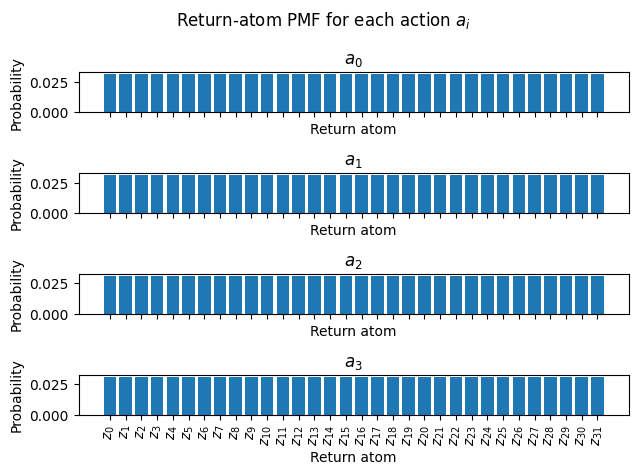

In [15]:
# Inspect density matrices before training.
# Preserve the observation that was used to compare inspect after training.
atoms = jnp.linspace(start=config.z_min, stop=config.z_max, num=config.num_atoms)
obs_inspect, _ = inspect_model_pmfs_for_env(config.env.make(), config.model, atoms)

In [53]:
from qnrl.metric import LocalFileMetricManager, WandBMetricManager


do_train = True
save_metrics = True
###
metric_filepath = Path(f"./metrics/{cfg_hash}")
# metric_manager = LocalFileMetricManager(
#     metric_dir=metric_filepath.resolve(),
#     metric_file_type="json",
#     save_interval_steps=1,
#     max_to_keep=1,
#     )
###
# metric_manager = WandBMetricManager(
#     login=False, # Already logged in at beginning of notebook.
#     project="qnrl",
#     name=f"c51/{env_id}/{cfg_hash}",
#     config=config.to_dict(),
#     monitor_gym=False,
#     save_code=True, # Preserve notebook.
#     terminate_on_wait_until_finished=False,
#     define_metrics=[
#         {"name": "*", "summary": "min"},
#         {"name": "*", "summary": "max"},
#         {"name": "*", "summary": "mean"},
#         {"name": "*", "summary": "first"},
#         {"name": "*", "summary": "last"},
#     ],
# )

In [54]:
# if metric_filepath.exists() and not train:
if not do_train:
    print(f"Loading existing train results")
    print(f"Store: {store.path}")
    print(f"Hash: {cfg_hash}")
    print(f"History: {metric_filepath}")
    history_list = qnrl.tools.load_train_results(metric_filepath)
    history_dict = qnrl.tools.listofdict_to_dictoflist(history_list)
else:
    print(f"Training")
    print(f"Store: {store.path}")
    print(f"Hash: {cfg_hash}")
    print(f"History: {metric_filepath}")
    
    train_history_df, train_report = config.train(
        # metric_manager=metric_manager if save_metrics else None,
    )
    # history_dict = qnrl.tools.listofdict_to_dictoflist(history_list)
    
    # # Preserve training results.
    # if save_metrics:
    #     qnrl.tools.save_train_results(metric_filepath, history_list)

Training
Store: hashstore.json
Hash: 893408fe-b4f7-5984-8cce-03ff4277688f
History: metrics/893408fe-b4f7-5984-8cce-03ff4277688f


 10%|▉         | 9959/100000 [00:09<01:27, 1025.19step/s, train/step=9976, train/episode_reward=15, train/episode_length=15, train/episode_time=0.014]  /Users/derieux/research/qnrl/.venv/lib/python3.12/site-packages/jax/_src/ops/scatter.py:108: FutureWarning: scatter inputs have incompatible types: cannot safely cast value from dtype=float64 to dtype=float32 with jax_numpy_dtype_promotion='standard'. In future JAX releases this will result in an error.
  warnings.warn(
100%|██████████| 100000/100000 [02:08<00:00, 777.16step/s, train/step=1e+5, train/episode_reward=334, train/episode_length=334, train/episode_time=0.444, train/loss=0.228, train/cross_entropy=0.231, train/kl_div=0.0139]  


In [55]:
train_report

{'train/seed': 0,
 'train/total_model_parameter_count': 2209,
 'train/step.mean': 51663.29450571091,
 'train/step.std': 27606.366753240807,
 'train/step.min': 17.0,
 'train/step.max': 99990.0,
 'train/episode_reward.mean': 79.49516129032259,
 'train/episode_reward.std': 94.10728328630279,
 'train/episode_reward.min': 8.0,
 'train/episode_reward.max': 500.0,
 'train/episode_length.mean': 79.49516129032259,
 'train/episode_length.std': 94.10728328630279,
 'train/episode_length.min': 8.0,
 'train/episode_length.max': 500.0,
 'train/episode_time.mean': 0.10187088225806451,
 'train/episode_time.std': 0.1276397134820741,
 'train/episode_time.min': 0.007753,
 'train/episode_time.max': 0.676177,
 'train/loss.mean': 0.7855920962437098,
 'train/loss.std': 0.8728229160116748,
 'train/loss.min': 0.09570904076099396,
 'train/loss.max': 3.497304916381836,
 'train/cross_entropy.mean': 0.7875415779892796,
 'train/cross_entropy.std': 0.8719767725573554,
 'train/cross_entropy.min': 0.09893308579921722,


In [18]:
train_history_df.describe()

,train/step,train/episode_reward,train/episode_length,train/episode_time,train/loss,train/cross_entropy,train/kl_div
count,9978.000000,1004.000000,1004.000000,1004.000000,8999.000000,8999.000000,8999.000000
mean,54430.183303,-414.827689,98.599602,0.123565,2.677765,2.677786,0.023704
std,26308.790494,356.959266,4.160901,0.020154,0.475202,0.475211,0.033134
min,98.000000,-2079.000000,29.000000,0.034765,1.885300,1.885323,0.000068
25%,31772.500000,-594.000000,99.000000,0.117158,2.217458,2.217462,0.000986
50%,54445.000000,-297.000000,99.000000,0.125744,2.675603,2.675603,0.007360
75%,77117.500000,-198.000000,99.000000,0.132200,3.110365,3.110393,0.035751
max,99996.000000,-29.000000,99.000000,0.461014,3.468596,3.468651,0.237036


Text(0, 0.5, 'episode_reward')

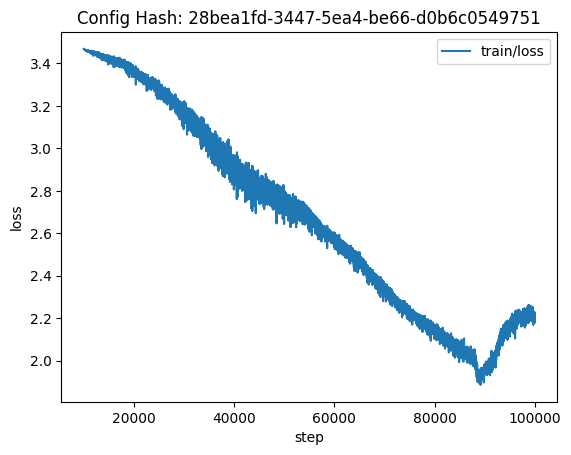

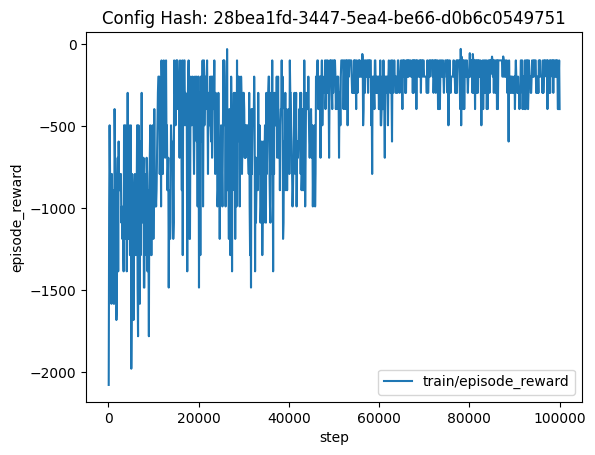

In [21]:
import matplotlib.pyplot as plt

# history_dict = qnrl.tools.listofdict_to_dictoflist(qnrl.tools.load_train_results(metric_filepath))
# metric_manager.load()
# history_dict = metric_manager.get_dataframe()

plt.figure()
ax = plt.gca()
plt.title(f"Config Hash: {cfg_hash}")
# plt.plot(history_dict['train/loss_step'].dropna(), history_dict['train/loss'].dropna())
train_history_df.set_index('train/step')[['train/loss']].dropna().plot(kind="line", ax=ax)
plt.xlabel('step')
plt.ylabel('loss')

plt.figure()
ax = plt.gca()
plt.title(f"Config Hash: {cfg_hash}")
# plt.plot(history_dict['train/episode_step'].dropna(), history_dict['train/episode_reward'].dropna())
train_history_df.set_index('train/step')[['train/episode_reward']].dropna().plot(kind="line", ax=ax)
plt.xlabel('step')
plt.ylabel('episode_reward')

In [15]:
# # Plot loss and episode reward on the same plot.

# history_dict = qnrl.tools.listofdict_to_dictoflist(qnrl.tools.load_train_results(metric_filepath))

# fig, axs = plt.subplots(2,1, sharex=True, figsize=(10,8))
# axs = axs.squeeze()

# axs[0].set_title(f"Config Hash: {cfg_hash}")
# plt.xlabel('step')

# # Only consider data points that are after learning starts (because this is where loss starts accumulating).
# idx = np.array(history_dict['loss_step']) >= config.learning_starts
# history_dict['loss_step'] = np.array(history_dict['loss_step'])[idx]
# history_dict['loss'] = np.array(history_dict['loss'])[idx]

# # Only consider data points that are after learning starts (because this is where loss starts accumulating).
# idx = np.array(history_dict['episode_step']) >= config.learning_starts
# history_dict['episode_step'] = np.array(history_dict['episode_step'])[idx]
# history_dict['episode_reward'] = np.array(history_dict['episode_reward'])[idx]

# axs[0].plot(history_dict['loss_step'], history_dict['loss'])
# axs[0].set_ylabel('loss')
# axs[0].grid() # Turn on a grid.

# axs[1].plot(history_dict['episode_step'], history_dict['episode_reward'])
# axs[1].set_ylabel('episode_reward')
# axs[1].grid() # Turn on a grid.

# # Save the figure file.
# figfile = f"./figures/{cfg_hash}.pdf"
# fig.savefig(figfile)
# print(figfile)

In [16]:
# ###
# # Inspect the metrics.
# ###
# idxmax = history_dict['episode_reward'] == max(history_dict['episode_reward'])
# idxmin = history_dict['episode_reward'] == min(history_dict['episode_reward'])

# firstmax = sorted(list(zip(history_dict['episode_step'][idxmax], history_dict['episode_reward'][idxmax])), key=lambda tup: tup[0])[0]
# firstmin = sorted(list(zip(history_dict['episode_step'][idxmin], history_dict['episode_reward'][idxmin])), key=lambda tup: tup[0])[0]

# print(f"{firstmax = }")
# print(f"{firstmin = }")

In [15]:
# eval_metric_list = config.eval()

In [16]:
plt.ioff()
eval_history_df, eval_report = config.eval()
# eval_metric_list = config.eval()
# eval_metric_dict = qnrl.tools.listofdict_to_dictoflist(eval_metric_list)

# for key in ('eval/episode_step','eval/episode_reward','eval/episode_length','eval/episode_time',):
#     print(f"{key}: {eval_metric_dict[key][0]}")

  0%|          | 98/100000 [00:00<00:23, 4247.75step/s, eval/step=98, eval/episode_reward=-99, eval/episode_length=99, eval/episode_time=0.0229]

observations = Array([[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0]], dtype=int8)
Q(a0): -77.62554183775079
Q(a1): -94.89543471098575
Q(a2): -78.09743488736962
Q(a3): -78.04552292415589
best_action.item() = 0


<Figure size 640x480 with 0 Axes>

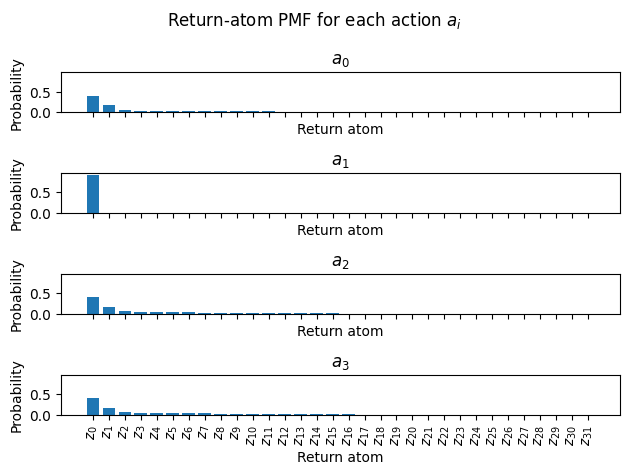

In [18]:
# Inspect the model again using the same observation used prior to training.
figures = inspect_model_pmfs_for_observation(obs_inspect, config.model, atoms)

metric_manager.run.log({"inspect_model_pmfs_for_observation": [wandb.Image(f) for f in figures], "observation": obs_inspect})

In [19]:
# obs_tmp=jnp.array([ 0.01716913, -0.02654778, -0.04510068, -0.00686742])
# inspect_model_pmfs_for_observation(obs_tmp, config.model, atoms)

In [20]:
# inspect_model_pmfs_for_observation(jnp.array([-0.01053775,  0.03950866, -0.03218421, -0.04678081]), config.model, atoms)

In [21]:
eval_metric_list = config.eval()
eval_metric_dict = qnrl.tools.listofdict_to_dictoflist(eval_metric_list)

for key in ('eval/episode_step','eval/episode_reward','eval/episode_length','eval/episode_time',):
    print(f"{key}: {eval_metric_dict[key][0]}")

  0%|          | 98/100000 [00:00<00:25, 3921.11step/s, eval/episode_step=98, eval/episode_reward=-99, eval/episode_length=99, eval/episode_time=0.0252]

eval/episode_step: 98
eval/episode_reward: -99.0
eval/episode_length: 99
eval/episode_time: 0.025237


In [131]:
eval_history_df, eval_report = config.eval(seed=0)

  0%|          | 98/100000 [00:00<02:27, 677.65step/s, eval/step=98, eval/episode_reward=-99, eval/episode_length=99, eval/episode_time=0.144]


variable: 9.875002433545887e-06
frame: 0.03687691599770915
canvas: 0.10343916699639522
variable: 1.8832994101103395e-05
frame: 0.039150999997218605
canvas: 0.11220483299985062
variable: 2.2499996703118086e-05
frame: 0.039936958004545886
canvas: 0.11144633300136775
variable: 1.9166000129189342e-05
frame: 0.037848874999326654
canvas: 0.10257124999770895
variable: 2.0209001377224922e-05
frame: 0.03706720800255425
canvas: 0.10549191700556548
variable: 2.0666993805207312e-05
frame: 0.03727074999915203
canvas: 0.10059045900561614
variable: 1.8500002624932677e-05
frame: 0.0365959170012502
canvas: 0.09535612500621937
variable: 1.8124999769497663e-05
frame: 0.03881304099923
canvas: 0.1060080419993028
variable: 2.058300015050918e-05
frame: 0.03941708300408209
canvas: 0.09981595900171669
variable: 2.099999983329326e-05
frame: 0.0362996670010034
canvas: 0.10131820899550803
variable: 1.8874998204410076e-05
frame: 0.036736833993927576
canvas: 0.09416612499626353
variable: 1.8500002624932677e-05
fram

In [132]:
len(eval_history_df)

99

In [135]:
from qnrl.algorithms.c51 import generate_video_from_history
clip = generate_video_from_history(eval_history_df, meta_prefix_key="eval/", fps=15)
# clip = moviepy.ImageSequenceClip(generate_video_from_history(eval_history_df, meta_prefix_key="eval/"), fps=5)
# clip.preview()
# moviepy.display_in_notebook(clip, loop=True, autoplay=True)
# clip.fx(moviepy.vfx.loop, duration=10)

UnboundLocalError: cannot access local variable 'matplotlib' where it is not associated with a value

In [105]:
clip = generate_video_from_history(eval_history_df, meta_prefix_key="eval/", fps=15)
frames_for_wandb = np.stack(list(clip.iter_frames())).transpose(0,3,1,2)

from IPython.display import display
display(wandb.Video(frames_for_wandb, format="mp4", fps=15))

In [ ]:
# from qnrl.algorithms.c51 import generate_video_frame

# frames = []
# for index, row in eval_history_df.iterrows():
#     frame = generate_video_frame(
#         env_render_frame=row["eval/frame"],
#         pmfs=row["eval/pmfs"],
#         q_vals=row["eval/q_vals"]
#     )
#     frames.append(frame)
# #     break
# # frame.set_size_inches(12,8)
# # frame



# import moviepy

# # from moviepy.video.io import mplfig_to_npimage as fig_to_numpy
# # from moviepy.tools import 
# # from moviepy.video.io.bindings import mplfig_to_npimage


# def fig_to_numpy(fig):
#     fig.canvas.draw()
#     # data = np.frombuffer(fig.canvas.tostring_argb(), dtype=np.uint8)
#     # return data.reshape((*fig.canvas.get_width_height()[::-1],4))

#     return np.asarray(fig.canvas.buffer_rgba())

# # fig_to_numpy(eval_report['eval/inspect'][0]['fig/q_values']).shape

# # fig_to_numpy = lambda fig: np.frombuffer(fig.canvas.tostring_argb(), dtype=np.uint8).reshape((*fig.canvas.get_width_height()[::-1],4))

# # clip = moviepy.ImageSequenceClip(list(fig_to_numpy(d['fig/q_values']) for d in eval_report['eval/inspect']), fps=10)
# clip = moviepy.ImageSequenceClip(list(fig_to_numpy(f) for f in frames), fps=5)
# clip.preview()

OSError: [Errno 32] Broken pipe

MoviePy error: FFPLAY encountered the following error while previewing clip :

 None

In [18]:
# Evaluate multiple times and preserve results.
# n_runs = 10
# n_runs = 50
n_runs = 100
# n_runs = 1000
# eval_metric_dict_runs = []
eval_runs_list = []
key = jax.random.PRNGKey(seed=config.seed)
for r in range(n_runs):
    
    # Generate a new random key.
    key, subkey = jax.random.split(key=key)
    
    seed_eval = int(subkey[0])
    eval_history_df, eval_report = config.eval(seed=seed_eval)
    # eval_metric_dict = qnrl.tools.listofdict_to_dictoflist(eval_metric_list)
    # eval_metric_dict['eval/seed'] = [seed_eval]
    eval_runs_list.append(eval_report)
    
    # d = {k: v[0] for k, v in eval_metric_dict.items() if 'eval/' in k}
    # metric_manager.run.log(d)

eval_runs_df = pd.DataFrame(eval_runs_list)

# Report statistics across all runs.
for key in ('eval/step','eval/episode_reward','eval/episode_length','eval/episode_time',):
    # l = jnp.array([d[key] for d in eval_metric_dict_runs]) # Each key only has 1 entry.
    print(f"{key}: min: {eval_runs_df[key].min()}")
    print(f"{key}: max: {eval_runs_df[key].max()}")
    print(f"{key}: mean: {eval_runs_df[key].mean()}")
    print(f"{key}: std: {eval_runs_df[key].std()}")

  0%|          | 98/100000 [00:00<00:19, 5182.98step/s, eval/step=98, eval/episode_reward=-99, eval/episode_length=99, eval/episode_time=0.019]

eval/step: min: 98
eval/step: max: 98
eval/step: mean: 98.0
eval/step: std: 0.0
eval/episode_reward: min: -99.0
eval/episode_reward: max: -99.0
eval/episode_reward: mean: -99.0
eval/episode_reward: std: 0.0
eval/episode_length: min: 99
eval/episode_length: max: 99
eval/episode_length: mean: 99.0
eval/episode_length: std: 0.0
eval/episode_time: min: 0.017737
eval/episode_time: max: 0.025787
eval/episode_time: mean: 0.01886765
eval/episode_time: std: 0.001024236176352649


In [39]:
eval_report_df

,key,value
0,eval/seed,9.289819e+08
1,eval/total_model_parameter_count,5.900000e+02
2,eval/step,9.800000e+01
3,eval/episode_reward,-9.900000e+01
4,eval/episode_length,9.900000e+01
5,eval/episode_time,2.087400e-02


## Record a run as a video

tmpdir = '/var/folders/t7/1jlv9_sn36g96901km63r92m0000gn/T/tmp5l61_86r'


/Users/derieux/research/qnrl/.venv/lib/python3.12/site-packages/gymnasium/wrappers/rendering.py:293: UserWarning: WARN: Overwriting existing videos at /var/folders/t7/1jlv9_sn36g96901km63r92m0000gn/T/tmp5l61_86r folder (try specifying a different `video_folder` for the `RecordVideo` wrapper if this is not desired)
  logger.warn(
/Users/derieux/research/qnrl/.venv/lib/python3.12/site-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists
  0%|          | 98/100000 [00:00<01:16, 1310.25step/s, eval/episode_step=98, eval/episode_reward=-99, eval/episode_length=99, eval/episode_time=0.332]


eval/episode_step: min: 98
eval/episode_step: max: 98
eval/episode_step: mean: 98.0
eval/episode_step: std: 0.0
eval/episode_reward: min: -99.0
eval/episode_reward: max: -99.0
eval/episode_reward: mean: -99.0
eval/episode_reward: std: 0.0
eval/episode_length: min: 99
eval/episode_length: max: 99
eval/episode_length: mean: 99.0
eval/episode_length: std: 0.0
eval/episode_time: min: 0.331648
eval/episode_time: max: 0.331648
eval/episode_time: mean: 0.331648
eval/episode_time: std: 0.0
os.listdir(tmpdir) = ['rl-video-episode-0.mp4']
MoviePy - Building file /var/folders/t7/1jlv9_sn36g96901km63r92m0000gn/T/tmp5l61_86r/rl-video-episode-0.gif with imageio.


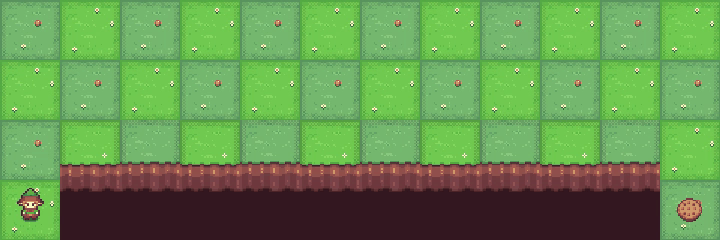

In [23]:
import os
import tempfile
from IPython.display import display, Video, Image
from moviepy import VideoFileClip

with tempfile.TemporaryDirectory() as tmpdir:
    print(f"{tmpdir = }")

    # Create wrapper for recording video.
    env_wrappers = [
        lambda env: gym.wrappers.RecordVideo(env, video_folder=tmpdir, episode_trigger=lambda x: True, disable_logger=True),
    ]
    
    # Evaluate multiple times and preserve results.
    n_runs = 1
    eval_metric_dict_runs = []
    key = jax.random.PRNGKey(seed=1423)
    for r in range(n_runs):
        
        # Generate a new random key.
        key, subkey = jax.random.split(key=key)
        
        # Evaluate the model within environment seeded from random subkey.
        eval_metric_list = config.eval(seed=int(subkey[0]), env=config.env.make(render_mode='rgb_array'), model_policy=config.model, total_timesteps=config.total_timesteps, env_wrappers=env_wrappers)
        eval_metric_dict = qnrl.tools.listofdict_to_dictoflist(eval_metric_list)
        eval_metric_dict['seed'] = int(subkey[0])
        eval_metric_dict_runs.append(eval_metric_dict)

    # Report statistics across all runs.
    for key in ('eval/episode_step','eval/episode_reward','eval/episode_length','eval/episode_time',):
        l = jnp.array([d[key][0] for d in eval_metric_dict_runs]) # Each key only has 1 entry.
        print(f"{key}: min: {jnp.min(l)}")
        print(f"{key}: max: {jnp.max(l)}")
        print(f"{key}: mean: {jnp.mean(l)}")
        print(f"{key}: std: {jnp.std(l)}")
    
    print(f"{os.listdir(tmpdir) = }")
    
    videofilepath = Path(tmpdir)/os.listdir(tmpdir)[0]
    
    # Build a GIF from the video file.
    giffilepath = Path(tmpdir)/(videofilepath.stem + '.gif')
    clip = VideoFileClip(videofilepath)
    clip.write_gif(giffilepath, fps=15)
    
    # display(Video(videofilepath, embed=True, html_attributes="controls muted loop autoplay"))
    display(Image(filename=giffilepath))

In [24]:
metric_manager.run.finish()

eval/episode_length,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
eval/episode_reward,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
eval/episode_step,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
eval/episode_time,█▂▂▂▂▂▁▂▁▂▂▂▂▁▂▁▁▂▄▂▂▂▁▁▁▂▂▂▂▁▂▂▂▂▂▂▁▂▂▂
eval/seed,▄▃▇▆▇▃▇█▆▆▄▄▂▇▂▆▂▁▃▆▁▂▄▆▂▆█▂▇▆▁▂▄▆▁▅█▂▂█
train/cross_entropy,█████████▇▇▇▇▆▆▆▅▅▅▅▅▄▄▄▄▃▃▃▂▂▂▂▁▁▁▁▁▂▂▂
train/episode_length,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
train/episode_reward,▁▄▇▇▅▇▇▄▅▃▁▇▆▇█▅▆▅▇█▇▇██▇▆▆▇▇█▇▇▇███▇▇▇█
train/episode_step,▁▁▂▂▂▂▂▃▃▃▃▄▄▄▄▅▅▅▅▅▅▆▆▆▆▆▆▇▇▇▇▇▇▇▇█████
train/episode_time,▄▄▇▇█▇▇██▇█▇▇████▇▇▇███████████▇█▁█▇████
+4,...


In [25]:
# Print all the parameters.
nnx.state(config.model, nnx.Param)

State({
  'layers': {
    'QNetworkLinear': {
      'layers': {
        0: {
          'bias': Param( # 4 (16 B)
            value=Array([-0.17506447, -0.0600759 ,  0.23703729,  0.2452549 ], dtype=float32)
          ),
          'kernel': Param( # 192 (768 B)
            value=Array([[ 0.15507695, -0.16585161, -0.32903025, -0.2582197 ],
                   [-0.13471025, -0.15079448, -0.24624394, -0.25083295],
                   [ 0.22355527, -0.26875362, -0.318192  , -0.21643989],
                   [-0.17614196, -0.15739505, -0.24080178, -0.26409152],
                   [ 0.17250197, -0.1550936 , -0.3248583 , -0.24813955],
                   [-0.0986914 , -0.16813815,  0.06707824, -0.06234371],
                   [ 0.15665878, -0.15411177, -0.18722735, -0.26163062],
                   [-0.31252292, -0.15025328, -0.24330777, -0.2488576 ],
                   [-0.09170465, -0.09822705, -0.07232417, -0.27152243],
                   [-0.25262624, -0.15893136, -0.269937  ,  0.91023034],
    